
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona - Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>

# Método de Jacobi: Computación Secuencial y Paralela en Python

### Análisis de rendimiento con matrices de 10,000 × 10,000

**Descripción del proyecto**

Este proyecto implementa el método iterativo de Jacobi para resolver un sistema de ecuaciones lineales de gran dimensión utilizando Python y Google Colab. Se trabaja con una matriz dispersa de **10,000 × 10,000 elementos**, estrictamente diagonalmente dominante, para favorecer la convergencia del algoritmo y optimizar el uso de memoria.

El objetivo principal es comparar el rendimiento de dos implementaciones del método de Jacobi: una **secuencial** y otra **paralela**, utilizando Numba para compilar y optimizar los cálculos numéricos.

### Objetivos

- Construir una matriz dispersa y diagonalmente dominante.
- Implementar el método de Jacobi mediante procesamiento secuencial y paralelo.
- Determinar el número de iteraciones necesarias para alcanzar una tolerancia de `1e-8`.
- Medir y comparar los tiempos de ejecución.
- Analizar la aceleración computacional (*speedup*) obtenida mediante paralelismo.

### Tecnologías utilizadas

**Python | NumPy | SciPy | Numba | Pandas | Matplotlib | Google Colab**

### Metodología

Se utiliza el formato de almacenamiento disperso **CSR (Compressed Sparse Row)** para reducir el consumo de memoria. Posteriormente, se implementan dos versiones del algoritmo de Jacobi, empleando `@njit` para la versión secuencial y `@njit(parallel=True)` junto con `prange` para la versión paralela.

Finalmente, se evalúan las soluciones mediante el error numérico, el número de iteraciones y el tiempo de procesamiento, presentando los resultados mediante tablas y visualizaciones comparativas.

**Área de aplicación:** Análisis numérico, álgebra lineal, optimización computacional y computación de alto rendimiento (HPC).

In [ ]:
# ============================================================
# Celda 2. Importar librerías
# ============================================================
import numpy as np
import scipy.sparse as sp
import time
import pandas as pd
import matplotlib.pyplot as plt

from numba import njit, prange, get_num_threads, set_num_threads


## 1. Parámetros del experimento

Se define el tamaño de la matriz, la tolerancia y el máximo de iteraciones.  
La tolerancia se usa para detener Jacobi cuando el cambio entre iteraciones es suficientemente pequeño.


In [ ]:
# ============================================================
# Celda 3. Parámetros
# ============================================================
n = 10_000              # Tamaño de la matriz: 10,000 x 10,000
tol = 1e-8              # Tolerancia deseada
max_iter = 20_000       # Máximo de iteraciones permitidas

# Colab a veces permite solo 2 hilos aunque se soliciten 4.
# Esta configuración evita el error.
try:
    hilos_disponibles = get_num_threads()
except Exception:
    hilos_disponibles = 1

num_threads = min(4, hilos_disponibles)
set_num_threads(num_threads)

print("Tamaño de la matriz:", n, "x", n)
print("Tolerancia:", tol)
print("Máximo de iteraciones:", max_iter)
print("Hilos disponibles para Numba:", hilos_disponibles)
print("Hilos configurados para Numba:", get_num_threads())

Tamaño de la matriz: 10000 x 10000
Tolerancia: 1e-08
Máximo de iteraciones: 20000
Hilos disponibles para Numba: 2
Hilos configurados para Numba: 2


## 2. Generación de matriz diagonalmente dominante

Para asegurar convergencia del método de Jacobi, se genera una matriz **estrictamente diagonalmente dominante**.

La matriz tiene una estructura dispersa tipo pentadiagonal:

- Diagonal principal con valor 10.
- Diagonales cercanas con valores negativos pequeños.
- Esto cumple que el valor absoluto de la diagonal principal es mayor que la suma de los valores absolutos fuera de la diagonal.


In [ ]:
# ============================================================
# Celda 4. Crear matriz dispersa diagonalmente dominante
# ============================================================
def crear_matriz_diagonalmente_dominante(n):
    """
    Crea una matriz dispersa n x n estrictamente diagonalmente dominante.
    Se usa formato CSR porque es eficiente para recorrer filas.
    """
    diagonal_principal = np.full(n, 10.0)
    diagonal_1 = np.full(n - 1, -1.0)
    diagonal_2 = np.full(n - 2, -0.5)

    A = sp.diags(
        diagonals=[diagonal_2, diagonal_1, diagonal_principal, diagonal_1, diagonal_2],
        offsets=[-2, -1, 0, 1, 2],
        shape=(n, n),
        format="csr"
    )
    return A

A = crear_matriz_diagonalmente_dominante(n)

# Se define una solución real conocida para comprobar el resultado.
x_real = np.ones(n)
b = A @ x_real

print("Matriz creada correctamente.")
print("Dimensión:", A.shape)
print("Elementos no cero:", A.nnz)
print("Densidad aproximada:", A.nnz / (n*n))


Matriz creada correctamente.
Dimensión: (10000, 10000)
Elementos no cero: 49994
Densidad aproximada: 0.00049994


## 3. Preparación de datos para Jacobi

En formato CSR, la matriz se almacena mediante tres arreglos:

- `data`: valores no cero.
- `indices`: columnas correspondientes.
- `indptr`: inicio y fin de cada fila.

Esto permite recorrer la matriz sin almacenar los ceros.


In [ ]:
# ============================================================
# Celda 5. Extraer datos CSR
# ============================================================
A_csr = A.tocsr()
data = A_csr.data.astype(np.float64)
indices = A_csr.indices.astype(np.int64)
indptr = A_csr.indptr.astype(np.int64)
diag = A_csr.diagonal().astype(np.float64)
b = b.astype(np.float64)

print("Datos CSR listos para Jacobi.")
print("data:", data.shape)
print("indices:", indices.shape)
print("indptr:", indptr.shape)
print("diag:", diag.shape)


Datos CSR listos para Jacobi.
data: (49994,)
indices: (49994,)
indptr: (10001,)
diag: (10000,)


## 4. Método de Jacobi secuencial

El método de Jacobi actualiza cada variable usando los valores de la iteración anterior.

Fórmula general:

$$
x_i^{(k+1)} = \frac{b_i - \sum_{j \neq i} a_{ij}x_j^{(k)}}{a_{ii}}
$$

La versión secuencial calcula fila por fila usando un solo flujo principal de ejecución.


In [ ]:
# ============================================================
# Celda 6. Jacobi secuencial con Numba
# ============================================================
@njit
def jacobi_secuencial(data, indices, indptr, diag, b, n, tol, max_iter):
    x = np.zeros(n, dtype=np.float64)
    x_new = np.zeros(n, dtype=np.float64)

    for it in range(max_iter):
        error = 0.0

        for i in range(n):
            suma = 0.0
            inicio = indptr[i]
            fin = indptr[i + 1]

            for k in range(inicio, fin):
                j = indices[k]
                if j != i:
                    suma += data[k] * x[j]

            x_new[i] = (b[i] - suma) / diag[i]
            diferencia = abs(x_new[i] - x[i])
            if diferencia > error:
                error = diferencia

        for i in range(n):
            x[i] = x_new[i]

        if error < tol:
            return x, it + 1, error

    return x, max_iter, error


## 5. Método de Jacobi paralelo

La versión paralela distribuye el cálculo de las filas entre varios hilos usando `prange` de Numba.  
Cada fila puede calcularse de forma independiente porque Jacobi usa los valores de la iteración anterior.


In [ ]:
# ============================================================
# Celda 7. Jacobi paralelo con Numba
# ============================================================
@njit(parallel=True)
def jacobi_paralelo(data, indices, indptr, diag, b, n, tol, max_iter):
    x = np.zeros(n, dtype=np.float64)
    x_new = np.zeros(n, dtype=np.float64)

    for it in range(max_iter):
        errores = np.zeros(n, dtype=np.float64)

        for i in prange(n):
            suma = 0.0
            inicio = indptr[i]
            fin = indptr[i + 1]

            for k in range(inicio, fin):
                j = indices[k]
                if j != i:
                    suma += data[k] * x[j]

            x_new[i] = (b[i] - suma) / diag[i]
            errores[i] = abs(x_new[i] - x[i])

        error = 0.0
        for i in range(n):
            if errores[i] > error:
                error = errores[i]
            x[i] = x_new[i]

        if error < tol:
            return x, it + 1, error

    return x, max_iter, error


## 6. Compilación previa

La primera vez que se ejecuta una función con Numba, se compila.  
Para que la comparación sea justa, se hace una corrida pequeña de calentamiento y **no se toma en cuenta** ese tiempo.


In [ ]:
# ============================================================
# Celda 8. Warm-up para compilar funciones Numba
# ============================================================
print("Compilando funciones de Numba...")

n_test = 100
A_test = crear_matriz_diagonalmente_dominante(n_test).tocsr()
x_test = np.ones(n_test)
b_test = (A_test @ x_test).astype(np.float64)

_ = jacobi_secuencial(
    A_test.data.astype(np.float64),
    A_test.indices.astype(np.int64),
    A_test.indptr.astype(np.int64),
    A_test.diagonal().astype(np.float64),
    b_test,
    n_test,
    1e-6,
    10
)

_ = jacobi_paralelo(
    A_test.data.astype(np.float64),
    A_test.indices.astype(np.int64),
    A_test.indptr.astype(np.int64),
    A_test.diagonal().astype(np.float64),
    b_test,
    n_test,
    1e-6,
    10
)

print("Compilación terminada.")


Compilando funciones de Numba...
Compilación terminada.


## 7. Ejecución secuencial

En esta celda se ejecuta Jacobi secuencial y se mide el tiempo.


In [ ]:
# ============================================================
# Celda 9. Ejecutar Jacobi secuencial
# ============================================================
inicio = time.perf_counter()
x_sec, iter_sec, error_sec = jacobi_secuencial(data, indices, indptr, diag, b, n, tol, max_iter)
fin = time.perf_counter()

tiempo_sec = fin - inicio

print("Resultado secuencial")
print("Iteraciones:", iter_sec)
print("Error final:", error_sec)
print("Tiempo de ejecución:", tiempo_sec, "segundos")


Resultado secuencial
Iteraciones: 17
Error final: 3.0132707440344575e-09
Tiempo de ejecución: 0.0020097050000345007 segundos


## 8. Ejecución paralela

En esta celda se ejecuta Jacobi paralelo y se mide el tiempo.


In [ ]:
# ============================================================
# Celda 10. Ejecutar Jacobi paralelo
# ============================================================
inicio = time.perf_counter()
x_par, iter_par, error_par = jacobi_paralelo(data, indices, indptr, diag, b, n, tol, max_iter)
fin = time.perf_counter()

tiempo_par = fin - inicio

print("Resultado paralelo")
print("Iteraciones:", iter_par)
print("Error final:", error_par)
print("Tiempo de ejecución:", tiempo_par, "segundos")


Resultado paralelo
Iteraciones: 17
Error final: 3.0132707440344575e-09
Tiempo de ejecución: 0.0058884350000312224 segundos


## 9. Comparación de resultados y speedup

El **speedup** mide cuántas veces más rápido fue el método paralelo respecto al secuencial.

$$
Speedup = \frac{T_{secuencial}}{T_{paralelo}}
$$


In [ ]:
# ============================================================
# Celda 11. Comparar tiempos, iteraciones y speedup
# ============================================================
speedup = tiempo_sec / tiempo_par

error_vs_real_sec = np.linalg.norm(x_sec - x_real, ord=np.inf)
error_vs_real_par = np.linalg.norm(x_par - x_real, ord=np.inf)

tabla_resultados = pd.DataFrame({
    "Método": ["Jacobi secuencial", "Jacobi paralelo"],
    "Iteraciones": [iter_sec, iter_par],
    "Error final entre iteraciones": [error_sec, error_par],
    "Error contra solución real": [error_vs_real_sec, error_vs_real_par],
    "Tiempo ejecución segundos": [tiempo_sec, tiempo_par],
    "Speedup": [1.0, speedup]
})

tabla_resultados


,Método,Iteraciones,Error final entre iteraciones,Error contra solución real,Tiempo ejecución segundos,Speedup
0,Jacobi secuencial,17,3.013271e-09,1.291402e-09,0.002010,1.000000
1,Jacobi paralelo,17,3.013271e-09,1.291402e-09,0.005888,0.341297


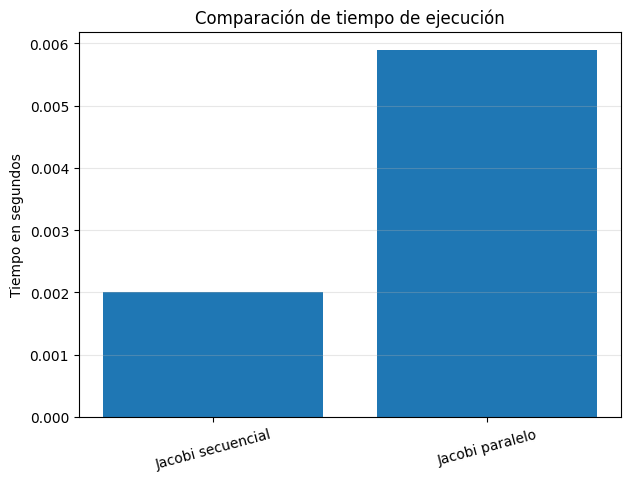

In [ ]:
# ============================================================
# Celda 12. Gráfica comparativa de tiempos
# ============================================================
plt.figure(figsize=(7, 5))
plt.bar(tabla_resultados["Método"], tabla_resultados["Tiempo ejecución segundos"])
plt.title("Comparación de tiempo de ejecución")
plt.ylabel("Tiempo en segundos")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.show()


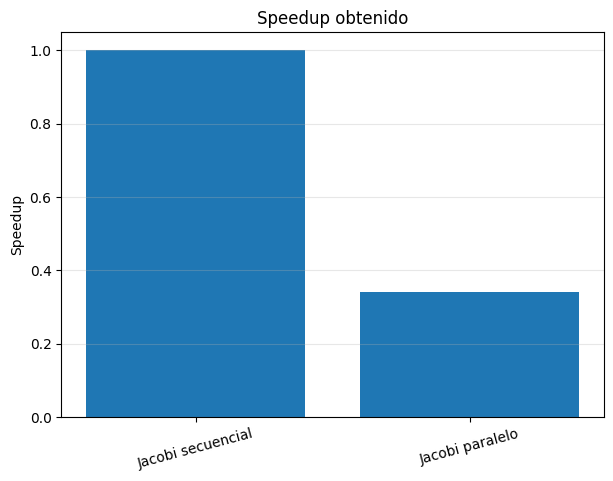

In [ ]:
# ============================================================
# Celda 13. Gráfica de speedup
# ============================================================
plt.figure(figsize=(7, 5))
plt.bar(tabla_resultados["Método"], tabla_resultados["Speedup"])
plt.title("Speedup obtenido")
plt.ylabel("Speedup")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.show()


\## 10. Prueba opcional con diferentes números de hilos

Esta celda permite observar cómo cambia el tiempo de ejecución al usar diferentes cantidades de hilos.  
Puede tardar más porque ejecuta el método paralelo varias veces.


In [ ]:
# ============================================================
# Celda 15. Gráfica speedup por número de hilos
# ============================================================
plt.figure(figsize=(7, 5))
plt.plot(resultados_hilos["Hilos"], resultados_hilos["Speedup contra secuencial"], marker="o")
plt.title("Speedup usando diferentes números de hilos")
plt.xlabel("Número de hilos")
plt.ylabel("Speedup")
plt.grid(True, alpha=0.3)
plt.show()


## 11. Conclusión para la práctica

En esta práctica se generó una matriz diagonalmente dominante de tamaño **10,000 × 10,000** en formato disperso. Se aplicó el método de Jacobi para encontrar una solución aproximada del sistema lineal.

El número mínimo de iteraciones se obtuvo cuando el error entre iteraciones fue menor que la tolerancia establecida. El tiempo de ejecución se midió usando `time.perf_counter()`.

Al comparar la versión secuencial con la paralela, el speedup permite observar si el uso de varios hilos mejora el rendimiento. En general, el método paralelo puede ser más rápido porque cada fila de Jacobi se puede calcular de manera independiente. Sin embargo, el speedup no siempre es perfecto debido a costos de sincronización, acceso a memoria, creación de hilos y limitaciones del hardware disponible en Google Colab.
